# Связь опоздания с низкими оценками

Это наблюдательное исследование, не A/B-тест. H0: доли низких оценок равны у late и on time. H1: отличаются. alpha=0.05, двусторонний тест.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)


In [2]:
from build_analysis import load_fact, START, END, statistical_analysis
fact=load_fact()
cohort=fact.loc[fact.order_purchase_timestamp.ge(START)&fact.order_purchase_timestamp.lt(END)].copy()
stats=statistical_analysis(cohort)
display(pd.read_csv(ROOT/'reports/tables/review_delivery_groups.csv'))


,is_late,reviewed_orders,low_reviews,low_review_rate,ci_low,ci_high
0,False,80541,7557,0.093828,0.091834,0.095861
1,True,5831,3721,0.638141,0.625720,0.650380


## Выборка

Один первый пригодный заказ с отзывом на customer_unique_id в периоде. Это уменьшает зависимость повторных заказов одного покупателя. Общие продавцы и временные шоки всё ещё могут создавать зависимость.

In [3]:
print('Пригодных заказов с отзывами:',stats['eligible_reviewed_orders'])
print('В основной выборке покупателей:',stats['primary_customers'])
print('Поздние:',stats['n_late'],'Своевременные:',stats['n_ontime'])


Пригодных заказов с отзывами: 89230
В основной выборке покупателей: 86372
Поздние: 5831 Своевременные: 80541


## Размер эффекта и интервалы

Доли сопровождаются 95% Wilson-интервалами, разность — Newcombe-интервалом. П.п. — процентные пункты, их нельзя путать с относительным изменением.

Доля низких оценок late: 63.81%
Доля низких оценок on time: 9.38%
Разность: 54.43 п.п.
95% CI разности, п.п.: [53.17, 55.67]
Risk ratio: 6.8
p: < 1e-300 log10(p): -3083.6


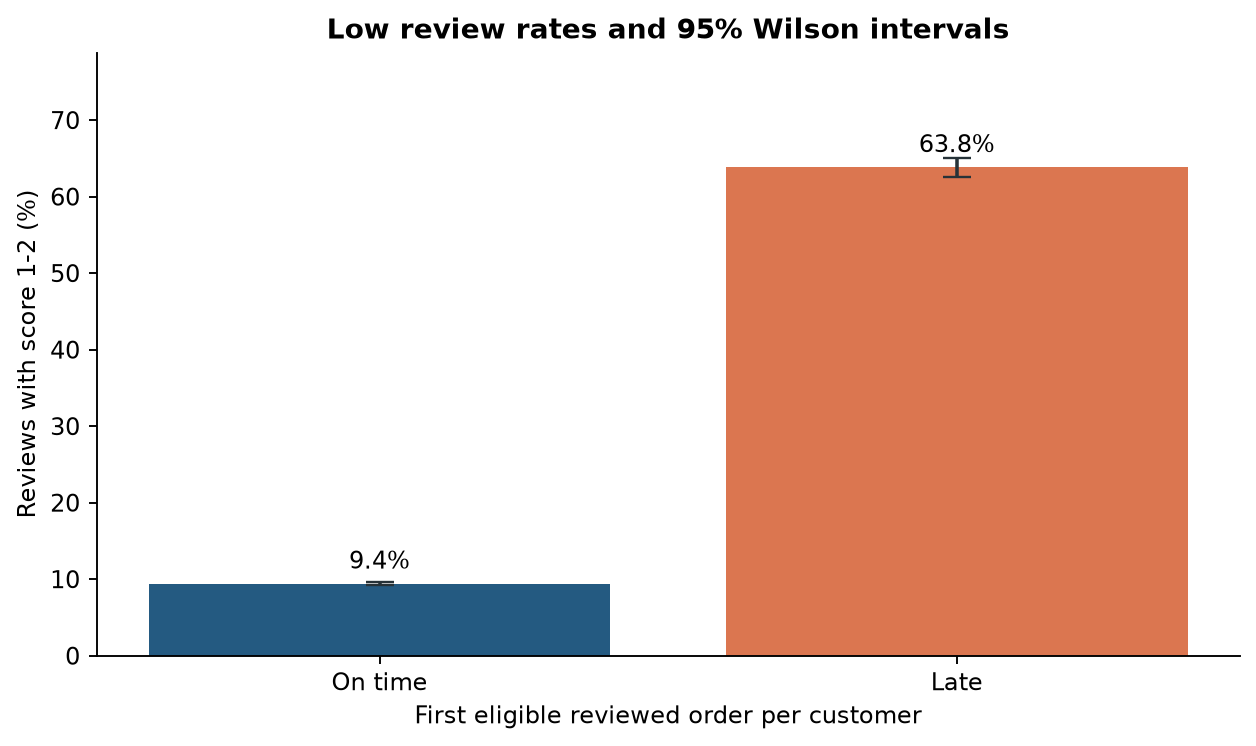

In [4]:
print('Доля низких оценок late:',f"{stats['rate_late']:.2%}")
print('Доля низких оценок on time:',f"{stats['rate_ontime']:.2%}")
print('Разность:',f"{stats['risk_difference']*100:.2f}",'п.п.')
print('95% CI разности, п.п.:',[round(x*100,2) for x in stats['risk_difference_ci']])
print('Risk ratio:',round(stats['risk_ratio'],2))
print('p:',stats['p_display'],'log10(p):',round(stats['log10_p_value'],1))
display(Image(filename=str(ROOT/'reports/figures/05_reviews_and_delivery.png')))


## Проверка чувствительности

Особенно важен момент написания отзыва. При отборе только ответов после получения меняется сама популяция, поэтому оценку нельзя напрямую трактовать как скорректированный причинный эффект.

In [5]:
display(pd.DataFrame([{k:v for k,v in s.items() if k!='groups'} for s in stats['sensitivity']]))
print('Разность после стандартизации state × month:',f"{stats['standardized_state_month_rd']*100:.2f}",'п.п.')
print('Страт:',stats['standardized_strata'],'Наблюдений:',stats['standardized_sample_n'])
for sample in stats['sensitivity']:
    print(sample['sample'])
    display(pd.DataFrame(sample['groups']))


,sample,n,risk_difference
0,all_eligible_reviewed_orders,89230,0.543117
1,answers_on_or_after_actual_delivery,82086,0.105386


Разность после стандартизации state × month: 49.77 п.п.
Страт: 108 Наблюдений: 62658
all_eligible_reviewed_orders


,is_late,n,low_reviews
0,False,83237,7807
1,True,5993,3817


answers_on_or_after_actual_delivery


,is_late,n,low_reviews
0,False,80434,7542
1,True,1652,329


## Интерпретация

Связь выражена, но её величина существенно чувствительна к времени отзыва. Малая p-value не устраняет смещение отбора, смешивающие факторы и зависимость наблюдений. Нельзя обещать, что устранение опозданий автоматически уменьшит низкие оценки на найденную разность. Следующий обоснованный шаг — детализация маршрутов и отдельно спроектированный пилот вмешательства.